# Ранжирование документов по поисковому запросу

In [1]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'transformers==4.57.1', 'sentencepiece>=0.2.0',
    'einops==0.8.1', 'lightgbm==4.6.0',
])


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


0

In [2]:
import gc
import hashlib
import html
import json
import math
import random
import re
import shutil
import time
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import torch
import torch.nn.functional as F
from sklearn.feature_extraction.text import CountVectorizer
from torch.utils.data import Dataset, DataLoader
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm
from IPython.display import display, FileLink

plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)


## 1. Настройки

Использую одну конфигурацию дообучения и AdamW. Разбиение, аугментации и число
обучаемых слоёв одинаковы для всех лоссов. Отдельные проверки размера батча,
learning rate и других оптимизаторов устойчивого улучшения на validation не дали. В данный ноутбук вставил основное


In [3]:
DATA_DIR = Path('/kaggle/input/datasets/krotslepoyyyy/ranked-data')
if not DATA_DIR.exists():
    DATA_DIR = Path('data')
TRAIN_PATH = DATA_DIR / 'train.csv'
TEST_PATH = DATA_DIR / 'test.csv'
WORK_DIR = Path('/kaggle/working/ranking_final') if Path('/kaggle/working').exists() else Path('outputs')
RESUME_ROOT = None  # Папка ranking_final из сохранённых Kaggle Outputs, если нужна.
RESUME = True
MAKE_SUBMISSION = True

MODEL_NAME = 'jinaai/jina-reranker-v2-base-multilingual'
MODEL_REVISION = '9cfeff2df7d40d1b78e75e5e9cebec92a99813c9'
RUN_TAG = 'ranking_final_v1'
SEED = 12345
SPLIT_SEED = 12345
DIAGNOSTIC_SEED = 12345
VAL_QUERY_SHARE = 0.15
NDCG_K = 10

MAX_LENGTH = 512
UNFREEZE_LAST_N = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
MAX_EPOCHS = 6
EARLY_STOPPING_PATIENCE = 2
QUERIES_PER_BATCH = 1
GRAD_ACCUM_STEPS = 2
EVAL_BATCH_SIZE = 32
EVALS_PER_EPOCH = 2
TRAIN_EVAL_QUERIES = 128
GRADIENT_CHECKPOINTING = True
AUGMENTATION = dict(mask_max_fraction=0.08, title_drop_prob=0.30)

REFERENCE_RANK_WEIGHT = 0.20
NDCG2PP_MU = 10.0
NDCG2PP_SIGMA = 1.0
CONTRASTIVE_TEMPERATURE = 1.0
BLEND_WEIGHTS = [0.0, 0.1, 0.25, 0.5]

WORK_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def save_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')
    temporary.replace(path)

def ids_digest(ids):
    return hashlib.sha256('\n'.join(sorted(ids)).encode()).hexdigest()

set_seed(SEED)


## 2. Данные и статистики


In [4]:
data = pd.read_csv(TRAIN_PATH, dtype=str, keep_default_na=False)
test = pd.read_csv(TEST_PATH, dtype=str, keep_default_na=False)
data['relevance'] = data.relevance.astype('int8')
data['row_id'] = np.arange(len(data))
if data.id.duplicated().any() or test.id.duplicated().any():
    raise ValueError('В id есть повторы.')
if not data.relevance.isin([0, 1]).all():
    raise ValueError('Ожидается бинарная relevance.')

overview = pd.DataFrame([
    dict(sample=name, pairs=len(frame), queries=frame.query_id.nunique(),
         documents=frame.document_id.nunique(), empty_titles=frame.title.str.strip().eq('').sum())
    for name, frame in [('train', data), ('test', test)]
])
display(overview)
display(pd.DataFrame({
    'train: пустые значения': data.eq('').sum(),
    'test: пустые значения': test.eq('').sum(),
}).fillna('—'))


,sample,pairs,queries,documents,empty_titles
0,train,31530,3042,27703,1382
1,test,13507,1305,11885,691


,train: пустые значения,test: пустые значения
article_char_count,2534,1275.0
article_id,0,0.0
article_passage_count,1959,1035.0
document_id,0,0.0
id,0,0.0
ingest_source,0,0.0
passage_index,1398,738.0
query,0,0.0
query_id,0,0.0
relevance,0,—


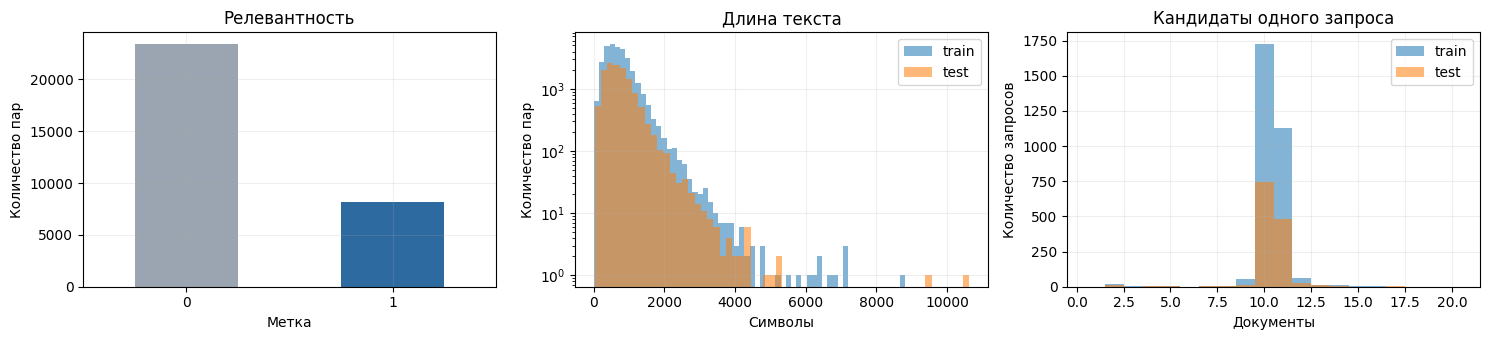

Запрос: Кто был основателем династии Меровингов?


,title,text,relevance
3407,Меровинги,"Первым историческим вождём салических франков большинство историков признают Хильдерика (около 457 — около 481), сына легендарного Меровея. Именно при нём будущая территория франкского королевства начала расширяться. Он сражался под предводительством римск...",1
3619,Меровинги,"Мерови́нги (, и ""Merovinger"") — первая в истории Франции династия франкских королей. Её короли правили с конца V до середины VIII века на территории современных Франции и Бельгии. Они происходили от салических франков, которые в V столетии обосновались в К...",0


Запрос: Что означает слово «Ретвиза́н»?


,title,text,relevance
1524,Ретвизан (броненосец),"«Ретвиза́н» — эскадренный броненосец русского флота. Назван в честь шведского линейного корабля «Rättvisan» («Справедливость»), захваченного в Выборгском сражении в 1790 году и вошедшего в состав русского флота. Помимо «пленника», это название в русском фл...",1
766,Реверсия (биология),"Реве́рсия (от — возвращение, возврат) — склонность к возвращению частей со смешанными признаками к исходным родительским формам; в более широком смысле понимается как атавизм вообще (например, в этом смысле термин применён в контексте химии в ЭСБЕ) или ка...",0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
data.relevance.value_counts().sort_index().plot.bar(ax=axes[0], color=['#9AA5B1', '#2D6A9F'], rot=0)
axes[0].set(title='Релевантность', xlabel='Метка', ylabel='Количество пар')
for name, frame in [('train', data), ('test', test)]:
    axes[1].hist(frame['text'].str.len(), bins=60, alpha=.55, label=name)
    axes[2].hist(frame.groupby('query_id').size(), bins=np.arange(1, 22)-.5,
                 alpha=.55, label=name)
axes[1].set(title='Длина текста', xlabel='Символы', ylabel='Количество пар', yscale='log')
axes[2].set(title='Кандидаты одного запроса', xlabel='Документы', ylabel='Количество запросов')
for axis in axes[1:]:
    axis.legend()
fig.tight_layout()
fig.savefig(WORK_DIR / 'data_overview.png', dpi=140, bbox_inches='tight')
plt.show()

example_queries = np.random.default_rng(SEED).choice(data.query_id.unique(), size=2, replace=False)
for query_id in example_queries:
    group = data.loc[data.query_id.eq(query_id)]
    print('Запрос:', group['query'].iloc[0])
    examples = pd.concat([group.loc[group.relevance.eq(label)].head(1) for label in [1, 0]])
    with pd.option_context('display.max_colwidth', 260):
        display(examples[['title', 'text', 'relevance']])


## 3. Предобработка и validation

Декодирую HTML-сущности, убираю разметку и технические пробелы, нормализую utf.
Регистр, пунктуацию и формы слов сохраняю. Документ для Jina - заголовок и текст.
Для train и test использую одну функцию подготовки

Около 15% запросов оставляю на validation. Запросы с общими `document_id`
или одинаковым нормализованным текстом попадают в одну компоненту и не разделяются.
Test используется только для предсказаний.


In [6]:
EMPTY_TITLES = {"", "null", "n/a", "—", "не указано"}
BLOCK_TAGS = re.compile(r"</?(?:p|div|br|li|ul|ol|h[1-6])\b[^>]*>", re.I)
INLINE_TAGS = re.compile(r"</?(?:span|b|i|strong|em|sup|sub|a)\b[^>]*>", re.I)

def safe_text(value):
    value = unicodedata.normalize("NFC", value)
    for _ in range(5):
        decoded = html.unescape(value)
        if decoded == value:
            break
        value = decoded
    value = BLOCK_TAGS.sub("\n", value)
    value = INLINE_TAGS.sub("", value)
    value = value.replace("\u00ad", "").replace("\u200b", "")
    value = value.replace("\u00a0", " ").replace("\u202f", " ")
    value = re.sub(r"[^\S\n]+", " ", value)
    value = unicodedata.normalize("NFD", value).replace("\u0301", "").replace("\u0300", "")
    return unicodedata.normalize("NFC", re.sub(r"\n{3,}", "\n\n", value).strip())


def prepare_frame(frame):
    frame = frame.copy()
    frame['query_clean'] = frame['query'].map(safe_text)
    titles = frame.title.mask(frame.title.str.strip().str.lower().isin(EMPTY_TITLES), '')
    frame['title_clean'] = titles.map(safe_text)
    frame['text_clean'] = frame['text'].map(safe_text)
    frame['document_clean'] = [t + '\n' + x if t else x
                               for t, x in zip(frame.title_clean, frame.text_clean)]
    return frame

data = prepare_frame(data)
test = prepare_frame(test)
changed = data.loc[data['text'].ne(data.text_clean)].sample(
    n=min(3, int(data['text'].ne(data.text_clean).sum())), random_state=SEED)
print('Примеры до и после очистки:')
with pd.option_context('display.max_colwidth', 220):
    display(changed[['text', 'text_clean']])


Примеры до и после очистки:


,text,text_clean
6857,"Основателем «Маяка» принято считать одного из будущих идеологов перестройки А. Н. Яковлева. Первым главным редактором его, как и всей Главной редакции информации («Последние известия» — «Маяк»), был Владимир Дмитриев...","Основателем «Маяка» принято считать одного из будущих идеологов перестройки А. Н. Яковлева. Первым главным редактором его, как и всей Главной редакции информации («Последние известия» — «Маяк»), был Владимир Дмитриев..."
18935,"Пу́блий (или ""Гай"") Корне́лий Та́цит (, или ; середина 50-х — ок. 120 года) — древнеримский историк, один из самых известных писателей античности, автор трёх небольших сочинений («Агри́кола», «Германия», «Диалог об о...","Публий (или ""Гай"") Корнелий Тацит (, или ; середина 50-х — ок. 120 года) — древнеримский историк, один из самых известных писателей античности, автор трёх небольших сочинений («Агрикола», «Германия», «Диалог об орато..."
8694,"Летом 1938 года Моррис согласился построить и управлять большим заводом в Кастл-Бромвич («Castle Bromwich») — районе графства Уэст-Мидлендс, предназначенным специально для строительства истребителей Супермарин Спитфа...","Летом 1938 года Моррис согласился построить и управлять большим заводом в Кастл-Бромвич («Castle Bromwich») — районе графства Уэст-Мидлендс, предназначенным специально для строительства истребителей Супермарин Спитфа..."


In [7]:
def canonical_query(value):
    value = safe_text(value).lower().replace("ё", "е")
    return " ".join(re.findall(r"\w+", value))

def query_components(frame):
    frame = frame.sort_values("id")
    parent = {q: q for q in frame.query_id.unique()}

    def root(q):
        while parent[q] != q:
            parent[q] = parent[parent[q]]
            q = parent[q]
        return q

    def join(values):
        first = root(values[0])
        for q in values[1:]:
            parent[root(q)] = first

    for _, group in frame.groupby("document_id", sort=False):
        join(group.query_id.unique())
    questions = frame[["query_id", "query"]].drop_duplicates().copy()
    questions["key"] = questions["query"].map(canonical_query)
    for _, group in questions.groupby("key", sort=False):
        join(group.query_id.tolist())
    return frame.query_id.map({q: root(q) for q in parent})

data["component"] = query_components(data)
component_sizes = data[["query_id", "component"]].drop_duplicates().groupby("component").size()
largest = component_sizes.idxmax()
candidates = np.random.default_rng(SPLIT_SEED).permutation(component_sizes.drop(index=largest).index)
chosen, total = [], 0
target = round(data.query_id.nunique() * VAL_QUERY_SHARE)
for component in candidates:
    size = int(component_sizes.loc[component])
    if abs(total + size - target) < abs(total - target):
        chosen.append(component)
        total += size

train = data.loc[~data.component.isin(chosen)].sort_values(["query_id", "id"]).copy()
val = data.loc[data.component.isin(chosen)].sort_values(["query_id", "id"]).copy()
sample_queries = np.random.default_rng(DIAGNOSTIC_SEED).choice(
    train.query_id.unique(), size=min(TRAIN_EVAL_QUERIES, train.query_id.nunique()), replace=False)
train_eval = train.loc[train.query_id.isin(sample_queries)].copy()

display(pd.DataFrame([
    dict(sample=name, queries=frame.query_id.nunique(), pairs=len(frame), positive_share=frame.relevance.mean())
    for name, frame in [("train", train), ("val", val), ("train_eval", train_eval)]
]).round(4))
data[["id", "query_id", "component"]].assign(
    split=np.where(data.component.isin(chosen), "val", "train")
).to_csv(WORK_DIR / "split.csv", index=False)


assert not set(train.component) & set(val.component)
print('Validation id SHA256:', ids_digest(val.id))


,sample,queries,pairs,positive_share
0,train,2586,26834,0.2602
1,val,456,4696,0.2528
2,train_eval,128,1307,0.2617


Validation id SHA256: fcdf870fcb9bee967a0387b7367c400e61f0fca19ad44b0fbe6a53c7193129e2


## 4. Метрика и сравнение результатов

Ранжирование строю отдельно внутри каждого запроса. При равных скорах использую
`id` для воспроизводимого порядка. 

In [8]:
def query_ndcg(frame, scores):
    ranked = frame[["query_id", "id", "relevance"]].copy()
    ranked["score"] = np.asarray(scores)
    ranked = ranked.sort_values(["query_id", "score", "id"], ascending=[True, False, True])
    ranked["rank"] = ranked.groupby("query_id").cumcount()+1
    ranked["gain"] = np.where(ranked["rank"] <= 10,
                              ranked.relevance/np.log2(ranked["rank"]+1), 0.0)
    dcg = ranked.groupby("query_id").gain.sum()
    positives = ranked.groupby("query_id").relevance.sum().clip(upper=10).astype(int)
    ideal_values = np.r_[0.0, np.cumsum(1/np.log2(np.arange(10)+2))]
    ideal = pd.Series(ideal_values[positives.to_numpy()], index=positives.index)
    return dcg.div(ideal.replace(0, np.nan)).fillna(0.0)


candidate_info = {}
val_predictions = {}

def add_candidate(key, label, scores, kind, **details):
    scores = np.asarray(scores, dtype=np.float32)
    if len(scores) != len(val) or not np.isfinite(scores).all():
        raise ValueError('Некорректные validation-предсказания: ' + key)
    val_predictions[key] = scores
    candidate_info[key] = dict(label=label, kind=kind,
        ndcg10=float(query_ndcg(val, scores).mean()), **details)
    predictions = val[['id', 'query_id', 'relevance']].copy()
    predictions['prediction'] = scores
    predictions.to_csv(WORK_DIR / f'{key}_val_predictions.csv', index=False)
    save_json(WORK_DIR / 'model_registry.json', candidate_info)

def comparison_table(keys=None):
    keys = list(candidate_info) if keys is None else keys
    rows = [dict(key=key, model=candidate_info[key]['label'],
                 ndcg10=candidate_info[key]['ndcg10'],
                 best_epoch=candidate_info[key].get('best_epoch'),
                 blend_weight=candidate_info[key].get('blend_weight')) for key in keys]
    return pd.DataFrame(rows).sort_values('ndcg10', ascending=False, kind='stable')

def plot_comparison(keys, title, filename):
    table = comparison_table(keys)
    display(table.drop(columns='key').round(6))
    fig, axis = plt.subplots(figsize=(9, max(3, len(table)*.45)))
    axis.barh(table.model[::-1], table.ndcg10[::-1], color='#2D6A9F')
    for y, value in enumerate(table.ndcg10[::-1]):
        axis.text(value + .006, y, f'{value:.5f}', va='center', fontsize=9)
    axis.set(xlabel='Validation NDCG@10', title=title, xlim=(0, 1.06))
    fig.tight_layout()
    fig.savefig(WORK_DIR / filename, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 5. BM25 и признаки для бустинга

BM25 чисто для проверки. Словарь строю на train

Для бустинга добавляю совпадения слов и чисел, длины, позицию фрагмента и размеры
статьи. Пропуски и некорректные метаданные обрабатываю явно. Айдишники
документов и статей в признаки не включаю


In [9]:
WORD_PATTERN = re.compile(r'(?u)\b\w+\b')
NUMBER_PATTERN = re.compile(r'\b\d+(?:[.,]\d+)?\b')

def lexical_tokens(value):
    return WORD_PATTERN.findall(value.casefold().replace('ё', 'е'))

class BM25:
    def __init__(self, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.vectorizer = CountVectorizer(tokenizer=lexical_tokens, token_pattern=None, lowercase=False)

    def fit(self, documents):
        matrix = self.vectorizer.fit_transform(documents).tocsr()
        document_frequency = np.asarray((matrix > 0).sum(axis=0)).ravel()
        self.idf = np.log1p((len(documents)-document_frequency+0.5)/(document_frequency+0.5))
        self.average_length = max(float(np.asarray(matrix.sum(axis=1)).mean()), 1.0)
        return self

    def score(self, frame, field):
        matrix = self.vectorizer.transform(frame[field]).tocsr()
        lengths = np.asarray(matrix.sum(axis=1)).ravel()
        scores = np.zeros(len(frame), dtype=np.float64)
        for positions in frame.groupby('query_id', sort=False).indices.values():
            query = frame.iloc[positions[0]].query_clean
            terms = self.vectorizer.transform([query]).indices
            if not len(terms):
                continue
            counts = matrix[positions][:, terms].tocoo()
            normalizer = self.k1*(1-self.b+self.b*lengths[positions[counts.row]]/self.average_length)
            weights = self.idf[terms[counts.col]]*counts.data*(self.k1+1)/(counts.data+normalizer)
            np.add.at(scores, positions[counts.row], weights)
        return scores.astype(np.float32)

class FeatureBuilder:
    def fit(self, frame):
        corpus = frame.drop_duplicates(['title_clean', 'text_clean'])
        self.title_bm25 = BM25().fit(corpus.title_clean.tolist())
        self.text_bm25 = BM25().fit(corpus.text_clean.tolist())
        self.sources = sorted(frame.ingest_source.unique())
        self.char_limit = float(pd.to_numeric(frame.article_char_count, errors='coerce').quantile(.995))
        return self

    def transform(self, frame):
        rows = []
        for q, title, body in zip(frame.query_clean, frame.title_clean, frame.text_clean):
            qw, tw, bw = (lexical_tokens(value) for value in [q, title, body])
            qs, ts, bs = set(qw), set(tw), set(bw)
            qn, tn, bn = (set(NUMBER_PATTERN.findall(value)) for value in [q, title, body])
            rows.append(dict(
                query_words=len(qw), title_words=len(tw), text_words=len(bw),
                log_title_chars=np.log1p(len(title)), log_text_chars=np.log1p(len(body)),
                query_title_coverage=len(qs & ts)/max(len(qs), 1),
                query_text_coverage=len(qs & bs)/max(len(qs), 1),
                query_title_jaccard=len(qs & ts)/max(len(qs | ts), 1),
                query_text_jaccard=len(qs & bs)/max(len(qs | bs), 1),
                number_title_coverage=len(qn & tn)/max(len(qn), 1),
                number_text_coverage=len(qn & bn)/max(len(qn), 1),
                query_has_number=int(bool(qn)), has_title=int(bool(title)),
            ))
        features = pd.DataFrame(rows)
        features['bm25_title'] = self.title_bm25.score(frame, 'title_clean')
        features['bm25_text'] = self.text_bm25.score(frame, 'text_clean')
        index = pd.to_numeric(frame.passage_index, errors='coerce').reset_index(drop=True)
        count = pd.to_numeric(frame.article_passage_count, errors='coerce').reset_index(drop=True)
        chars = pd.to_numeric(frame.article_char_count, errors='coerce').reset_index(drop=True)
        index = index.where(index.ge(0) & index.mod(1).eq(0))
        count = count.where(count.gt(0) & count.mod(1).eq(0))
        invalid_position = index.ge(count) & count.notna() & index.notna()
        index = index.mask(invalid_position)
        chars = chars.where(chars.gt(0)).clip(upper=self.char_limit)
        features['position_missing'] = index.isna().astype('int8')
        features['count_missing'] = count.isna().astype('int8')
        features['chars_missing'] = chars.isna().astype('int8')
        features['invalid_position'] = invalid_position.astype('int8')
        features['log_passage_index'] = np.log1p(index)
        features['log_passage_count'] = np.log1p(count)
        features['relative_position'] = index/(count-1).clip(lower=1)
        features['log_article_chars'] = np.log1p(chars)
        for number, value in enumerate(self.sources):
            features[f'source_{number}'] = frame.ingest_source.eq(value).to_numpy(dtype=np.int8)
        return features.astype('float32')

feature_builder = FeatureBuilder().fit(train)
X_train = feature_builder.transform(train)
X_val = feature_builder.transform(val)
bm25_val_scores = X_val.bm25_title.to_numpy() + X_val.bm25_text.to_numpy()
add_candidate('bm25', 'BM25', bm25_val_scores, kind='bm25')
display(X_train.head().round(3))
print('Признаков для бустинга:', X_train.shape[1], '| BM25 NDCG@10:', candidate_info['bm25']['ndcg10'])


,query_words,title_words,text_words,log_title_chars,log_text_chars,query_title_coverage,query_text_coverage,query_title_jaccard,query_text_jaccard,number_title_coverage,...,chars_missing,invalid_position,log_passage_index,log_passage_count,relative_position,log_article_chars,source_0,source_1,source_2,source_3
0,4.0,3.0,177.0,3.332,7.162,0.00,0.25,0.000,0.007,0.0,...,0.0,0.0,3.091,3.367,0.778,9.248,1.0,0.0,0.0,0.0
1,4.0,3.0,18.0,3.178,4.990,0.25,0.25,0.167,0.048,0.0,...,0.0,0.0,0.000,1.386,0.000,9.069,0.0,0.0,1.0,0.0
2,4.0,2.0,135.0,2.944,6.878,0.00,0.25,0.000,0.008,0.0,...,0.0,0.0,2.079,3.135,0.333,8.347,0.0,1.0,0.0,0.0
3,4.0,3.0,153.0,3.178,6.855,0.00,0.50,0.000,0.017,0.0,...,0.0,0.0,3.434,3.638,0.833,10.267,1.0,0.0,0.0,0.0
4,4.0,2.0,58.0,2.833,6.225,0.50,0.50,0.500,0.039,0.0,...,0.0,0.0,0.000,3.829,0.000,10.188,1.0,0.0,0.0,0.0


Признаков для бустинга: 27 | BM25 NDCG@10: 0.6604799224058666


## 6. Входы Jina и исходная модель

Использую `jina-reranker-v2-base-multilingual` как cross-encoder: запрос и документ
поступают совместно, на выходе получается один скор. Окно — 512 токенов. 
Для проверки смотрел с окном в 1024, качество на val было немного лучше, но с точки зрения оптимизации не вижу смысла и sample_submissions не формировал, не захотел

В обучении маскирую до 8% токенов текста и с вероятностью 30% убираю заголовок.
Также использовал Crop, но он как аугументация странный выбор (может скрыть полезную инфу) . Validation, train_eval и test всегда оцениваю без аугментаций (по базе).


In [10]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Для обучения Jina включите GPU в настройках Kaggle.')
try:
    native_bf16 = torch.cuda.is_bf16_supported(including_emulation=False)
except TypeError:
    native_bf16 = torch.cuda.get_device_capability()[0] >= 8
AMP_DTYPE = torch.bfloat16 if native_bf16 else torch.float16
print('GPU:', torch.cuda.get_device_name(), '| AMP:', AMP_DTYPE)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, use_fast=True)
PAIR_SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add(pair=True)
SPECIAL_IDS = set(tokenizer.all_special_ids)

def tokenize_frame(frame):
    query_parts, title_parts, text_parts = [], [], []
    for start in tqdm(range(0, len(frame), 256), desc='Токенизация'):
        part = frame.iloc[start:start+256]
        queries = tokenizer(part.query_clean.tolist(), add_special_tokens=False,
                            return_attention_mask=False, verbose=False)['input_ids']
        documents = tokenizer(part.document_clean.tolist(), add_special_tokens=False,
                              return_attention_mask=False, return_offsets_mapping=True, verbose=False)
        for q, ids, offsets, title in zip(queries, documents['input_ids'],
                                           documents['offset_mapping'], part.title_clean):
            prefix_length = len(title)+1 if title else 0
            split_at = next((j for j, (_, end) in enumerate(offsets) if end > prefix_length), len(ids))
            query_parts.append(q)
            title_parts.append(ids[:split_at])
            text_parts.append(ids[split_at:])
    return query_parts, title_parts, text_parts

query_tokens, title_tokens, text_tokens = tokenize_frame(data)


GPU: Tesla T4 | AMP: torch.float16


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

Токенизация:   0%|          | 0/124 [00:00<?, ?it/s]

,sample,field,minimum,mean,maximum,truncated_share
0,train,Текст,3,202.1885,3616,0.0257
1,train,Запрос + заголовок + текст,24,224.4853,3639,0.0300
2,val,Текст,10,205.0507,2958,0.0251
3,val,Запрос + заголовок + текст,29,227.5539,2977,0.0281


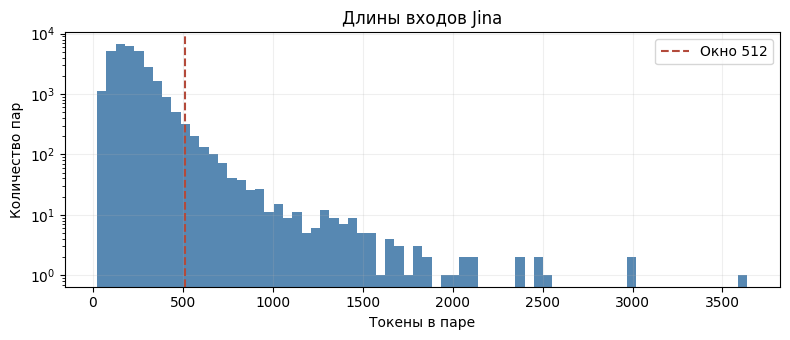

In [11]:
def build_pair_input(q, title, body, row_id=0, augment=False, epoch=0, augmentation=None):
    rng = random.Random(SEED + epoch*1_000_003 + int(row_id))
    profile = augmentation or AUGMENTATION
    if augment and title and rng.random() < profile['title_drop_prob']:
        title = []
    q = q[:MAX_LENGTH-PAIR_SPECIAL_TOKENS-1]
    budget = MAX_LENGTH-PAIR_SPECIAL_TOKENS-len(q)
    document = (title+body)[:budget]
    body_start = min(len(title), len(document))
    eligible = [i for i in range(body_start, len(document)) if document[i] not in SPECIAL_IDS]
    if augment and eligible:
        n_mask = int(len(eligible)*rng.uniform(0, profile['mask_max_fraction']))
        for position in rng.sample(eligible, n_mask):
            document[position] = tokenizer.mask_token_id
    ids = tokenizer.build_inputs_with_special_tokens(q, document)
    return dict(input_ids=ids, attention_mask=[1]*len(ids))

def make_input(row_id, augment=False, epoch=0, augmentation=None):
    return build_pair_input(query_tokens[row_id], title_tokens[row_id], text_tokens[row_id],
                            row_id, augment, epoch, augmentation)

clean_inputs = [make_input(i) for i in range(len(data))]
full_lengths = np.array([len(q)+len(t)+len(x)+PAIR_SPECIAL_TOKENS
                         for q, t, x in zip(query_tokens, title_tokens, text_tokens)])
length_rows = []
for name, frame in [('train', train), ('val', val)]:
    for field, values in [
        ('Текст', np.array([len(text_tokens[i]) for i in frame.index])),
        ('Запрос + заголовок + текст', full_lengths[frame.index]),
    ]:
        length_rows.append(dict(sample=name, field=field, minimum=int(values.min()),
            mean=float(values.mean()), maximum=int(values.max()), truncated_share=float((values > MAX_LENGTH).mean())))
display(pd.DataFrame(length_rows).round(4))
fig, axis = plt.subplots(figsize=(8, 3.5))
axis.hist(full_lengths, bins=70, color='#2D6A9F', alpha=.8)
axis.axvline(MAX_LENGTH, color='#B34A3B', linestyle='--', label='Окно 512')
axis.set(xlabel='Токены в паре', ylabel='Количество пар', yscale='log', title='Длины входов Jina')
axis.legend()
fig.tight_layout()
fig.savefig(WORK_DIR / 'token_lengths.png', dpi=140)
plt.show()


In [12]:
class QueryDataset(Dataset):
    def __init__(self, frame, augment=False, epoch=0, augmentation=None):
        self.groups = [group.index.to_numpy() for _, group in frame.groupby("query_id", sort=False)]
        self.augment = augment
        self.epoch = epoch
        self.augmentation = augmentation

    def __len__(self):
        return len(self.groups)

    def __getitem__(self, index):
        rows = self.groups[index]
        inputs = [make_input(int(i), self.augment, self.epoch,
                             augmentation=self.augmentation) for i in rows]
        labels = data.loc[rows, "relevance"].to_numpy(dtype=np.float32)
        return inputs, labels

def collate_queries(items):
    inputs = [example for group, _ in items for example in group]
    labels = torch.tensor(np.concatenate([labels for _, labels in items]), dtype=torch.float32)
    sizes = [len(group) for group, _ in items]
    batch = tokenizer.pad(inputs, padding=True, pad_to_multiple_of=8, return_tensors="pt")
    return batch, labels, sizes

class ScoreDataset(Dataset):
    def __init__(self, inputs):
        self.inputs = inputs
        self.order = np.argsort([len(x['input_ids']) for x in inputs], kind='stable')

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        position = int(self.order[index])
        return self.inputs[position], position

def collate_eval(items):
    inputs, positions = zip(*items)
    batch = tokenizer.pad(list(inputs), padding=True, pad_to_multiple_of=8, return_tensors='pt')
    return batch, np.array(positions)

def make_score_loader(inputs, batch_size=EVAL_BATCH_SIZE):
    return DataLoader(ScoreDataset(inputs), batch_size=batch_size, shuffle=False,
                      collate_fn=collate_eval, num_workers=0, pin_memory=DEVICE.type == 'cuda')

def make_eval_loader(frame):
    return make_score_loader([clean_inputs[i] for i in frame.index])

val_loader = make_eval_loader(val)
train_eval_loader = make_eval_loader(train_eval)


### Лоссы

Базовый вариант:
$L = L_{BCE} + 0.2L_{rank}$. В ranking положительный документ сравнивается
с отрицательным внутри запроса; веса пар зависят от изменения NDCG@10.

Два дополнительных варианта: $L_{BCE}+\alpha L_{NDCG2++}$ и
$L_{BCE}+\beta L_{contrastive}$. В NDCGLoss2++ 



In [13]:
def query_losses(scores, target):
    scores, target = scores.float(), target.float()
    zero = scores.sum() * 0.0
    result = dict(bce=F.binary_cross_entropy_with_logits(scores, target),
                  ranking=zero, ndcg2pp=zero, contrastive=zero)
    positive, negative = target > 0, target == 0
    if not positive.any() or not negative.any():
        return result

    with torch.no_grad():
        order = torch.argsort(scores.detach(), descending=True, stable=True)
        ranks = torch.empty_like(order)
        ranks[order] = torch.arange(len(scores), device=scores.device)
        discounts = 1.0 / torch.log2(ranks.float() + 2.0)
        ideal_count = min(int(positive.sum()), NDCG_K)
        ideal = (1.0 / torch.log2(torch.arange(ideal_count, device=scores.device).float() + 2)).sum()
        # Прежняя LambdaRank-подобная добавка: скидка за пределами top-k равна 0.
        cutoff_discounts = torch.where(ranks < NDCG_K, discounts, 0.0)
        old_weights = (cutoff_discounts[positive, None] - cutoff_discounts[None, negative]).abs() / ideal

        rp, rn = ranks[positive, None], ranks[None, negative]
        distance = (rp - rn).abs().float()  # Для разных документов distance >= 1.
        distance_weight = 1.0 / torch.log2(distance + 1) - 1.0 / torch.log2(distance + 2)
        lambda_weight = (discounts[positive, None] - discounts[None, negative]).abs()
        ndcg_weights = (NDCG2PP_MU * distance_weight + lambda_weight) / ideal
        active_pairs = (rp < NDCG_K) | (rn < NDCG_K)

    differences = scores[negative][None, :] - scores[positive][:, None]
    pair_loss = F.softplus(differences)
    result['ranking'] = (old_weights * pair_loss).sum() / old_weights.sum().clamp_min(1e-8)
    if active_pairs.any():
        weighted = ndcg_weights * F.softplus(NDCG2PP_SIGMA * differences) / math.log(2)
        result['ndcg2pp'] = weighted[active_pairs].mean()

    scaled = scores / CONTRASTIVE_TEMPERATURE
    negative_logsumexp = torch.logsumexp(scaled[negative], dim=0)
    result['contrastive'] = (torch.logaddexp(scaled[positive], negative_logsumexp) - scaled[positive]).mean()
    return result

def grouped_losses(logits, labels, sizes):
    rows = [query_losses(s, y) for s, y in zip(logits.split(sizes), labels.split(sizes))]
    return {name: torch.stack([row[name] for row in rows]).mean() for name in rows[0]}

def objective(parts, experiment):
    return parts['bce'] + experiment['aux_weight'] * parts[experiment['auxiliary']]


def clean_metrics(frame, scores):
    # train, val и train_eval заранее отсортированы по query_id и id.
    sizes = frame.groupby("query_id", sort=False).size().tolist()
    with torch.no_grad():
        parts = grouped_losses(torch.tensor(scores, dtype=torch.float32),
                               torch.tensor(frame.relevance.to_numpy(), dtype=torch.float32), sizes)
    result = {name: float(value) for name, value in parts.items()}
    result["ndcg10"] = float(query_ndcg(frame, scores).mean())
    return result


In [14]:
def load_jina(settings=None):
    settings = settings or dict(model=MODEL_NAME, revision=MODEL_REVISION, unfreeze_last_n=UNFREEZE_LAST_N)
    config = AutoConfig.from_pretrained(settings['model'], revision=settings['revision'], trust_remote_code=True)
    config.use_flash_attn = False
    config.use_cache = False
    model = AutoModelForSequenceClassification.from_pretrained(
        settings['model'], revision=settings['revision'], config=config,
        trust_remote_code=True, use_safetensors=True, dtype=torch.float32).to(DEVICE)
    model.requires_grad_(False)
    model.classifier.requires_grad_(True)
    count = settings['unfreeze_last_n']
    if not 0 <= count <= len(model.roberta.encoder.layers):
        raise ValueError('Недопустимое число обучаемых блоков.')
    model._trainable_block_count = count
    if count:
        for block in model.roberta.encoder.layers[-count:]:
            block.requires_grad_(True)
    return model

def set_training_mode(model):
    model.eval()
    count = model._trainable_block_count
    if count:
        for block in model.roberta.encoder.layers[-count:]:
            block.train()
    model.classifier.train()
    model.roberta.encoder.gradient_checkpointing = GRADIENT_CHECKPOINTING

def trainable_weights(model):
    return {name: p.detach().cpu().clone() for name, p in model.named_parameters() if p.requires_grad}

def load_partial_weights(model, weights):
    expected = {name for name, p in model.named_parameters() if p.requires_grad}
    if set(weights) != expected:
        raise ValueError('Набор изменённых параметров checkpoint не соответствует обучаемым блокам.')
    loaded = model.load_state_dict(weights, strict=False)
    if loaded.unexpected_keys:
        raise ValueError(f'Неизвестные параметры: {loaded.unexpected_keys}')

@torch.inference_mode()
def predict_scores(model, loader):
    model.eval()
    model.roberta.encoder.gradient_checkpointing = False
    scores = np.empty(len(loader.dataset), dtype=np.float32)
    for inputs, positions in loader:
        inputs = {key: value.to(DEVICE, non_blocking=True) for key, value in inputs.items()}
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
            logits = model(**inputs).logits.reshape(-1)
        scores[positions] = logits.float().cpu().numpy()
    if not np.isfinite(scores).all():
        raise RuntimeError('В предсказаниях есть NaN/inf.')
    return scores


In [15]:
set_seed(SEED)
pretrained_model = load_jina()
initial_val_scores = predict_scores(pretrained_model, val_loader)
initial_train_scores = predict_scores(pretrained_model, train_eval_loader)
add_candidate('jina_pretrained', 'Jina без дообучения', initial_val_scores, kind='neural', checkpoint=None)
del pretrained_model
gc.collect()
torch.cuda.empty_cache()

def calibrate_auxiliary_weights(frame, scores):
    logits = torch.tensor(scores, dtype=torch.float32, requires_grad=True)
    labels = torch.tensor(frame.relevance.to_numpy(), dtype=torch.float32)
    sizes = frame.groupby('query_id', sort=False).size().tolist()
    parts = grouped_losses(logits, labels, sizes)
    names = ['ranking', 'ndcg2pp', 'contrastive']
    norms = {name: float(torch.autograd.grad(parts[name], logits, retain_graph=True)[0].norm())
             for name in names}
    if any(not math.isfinite(value) or value <= 1e-12 for value in norms.values()):
        raise RuntimeError('Не удалось определить масштабы дополнительных лоссов.')
    target = REFERENCE_RANK_WEIGHT*norms['ranking']
    weights = {name: target/norms[name] for name in names}
    weights['ranking'] = REFERENCE_RANK_WEIGHT
    return weights, pd.DataFrame([dict(loss=name, coefficient=weights[name],
                                      initial_gradient_norm=norms[name]) for name in names])

auxiliary_weights, calibration_table = calibrate_auxiliary_weights(train_eval, initial_train_scores)
display(calibration_table.round(6))
calibration_table.to_csv(WORK_DIR / 'loss_coefficients.csv', index=False)

BASE_EXPERIMENT = dict(name='jina_finetuned', label='Jina + дообучение', auxiliary='ranking',
                       aux_weight=auxiliary_weights['ranking'], epochs=MAX_EPOCHS)
LOSS_EXPERIMENTS = [
    dict(name='jina_ndcg2pp', label='Jina + NDCGLoss2++', auxiliary='ndcg2pp',
         aux_weight=auxiliary_weights['ndcg2pp'], epochs=MAX_EPOCHS),
    dict(name='jina_contrastive', label='Jina + contrastive', auxiliary='contrastive',
         aux_weight=auxiliary_weights['contrastive'], epochs=MAX_EPOCHS),
]


config.json: 0.00B [00:00, ?B/s]

configuration_xlm_roberta.py: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


modeling_xlm_roberta.py: 0.00B [00:00, ?B/s]

xlm_padding.py: 0.00B [00:00, ?B/s]

mlp.py: 0.00B [00:00, ?B/s]

... (3 outputs left out)

I0000 00:00:1795123895.963545      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/557M [00:00<?, ?B/s]

You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


,loss,coefficient,initial_gradient_norm
0,ranking,0.200000,0.011983
1,ndcg2pp,0.080587,0.029739
2,contrastive,0.052029,0.046063


## 7. Дообучение на контрольном лоссе

Обучаю последние два блока и классификационную голову. Остальные параметры
заморожены. Лучший checkpoint выбираю по val NDCG@10; patience считаю по эпохам.
Train_eval — фиксированные 128 запросов из train без аугментаций.

Пробовал разные стратегии разморозки + лору, но что-то не пошло

In [16]:
def plot_history(history, directory, label):
    table = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    axes[0].plot(table.epoch, table.train_loss, '--', alpha=.6, label='train: аугментации')
    axes[0].plot(table.epoch, table.train_eval_loss, 'o-', label='train_eval')
    axes[0].plot(table.epoch, table.val_loss, 'o-', label='validation')
    axes[0].set_title('Целевая функция запуска')
    axes[1].plot(table.epoch, table.train_eval_bce, 'o-', label='train_eval')
    axes[1].plot(table.epoch, table.val_bce, 'o-', label='validation')
    axes[1].set_title('BCE')
    axes[2].plot(table.epoch, table.train_eval_ndcg10, 'o-', label='train_eval')
    axes[2].plot(table.epoch, table.val_ndcg10, 'o-', label='validation')
    axes[2].set_title('NDCG@10')
    for axis in axes:
        axis.set_xlabel('Эпоха')
        axis.legend(fontsize=8)
    fig.suptitle(label)
    fig.tight_layout()
    fig.savefig(directory / 'learning_curves.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def evaluation_row(model, experiment, epoch, step, online=None, fixed_scores=None):
    if fixed_scores is None:
        val_scores = predict_scores(model, val_loader)
        train_scores = predict_scores(model, train_eval_loader)
    else:
        val_scores, train_scores = fixed_scores
    vm = clean_metrics(val, val_scores)
    tm = clean_metrics(train_eval, train_scores)
    row = dict(epoch=float(epoch), step=int(step),
        train_loss=None if online is None else online['loss'],
        train_eval_loss=float(objective(tm, experiment)), val_loss=float(objective(vm, experiment)),
        train_eval_bce=tm['bce'], val_bce=vm['bce'],
        train_eval_ndcg10=tm['ndcg10'], val_ndcg10=vm['ndcg10'])
    return row, val_scores

data_hash = hashlib.sha256(TRAIN_PATH.read_bytes()).hexdigest()
common_config = dict(
    model=MODEL_NAME, revision=MODEL_REVISION, max_length=MAX_LENGTH,
    seed=SEED, split_seed=SPLIT_SEED, diagnostic_seed=DIAGNOSTIC_SEED,
    optimizer='AdamW', lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
    warmup=WARMUP_RATIO, unfreeze_last_n=UNFREEZE_LAST_N,
    queries_per_batch=QUERIES_PER_BATCH, grad_accum_steps=GRAD_ACCUM_STEPS,
    eval_batch_size=EVAL_BATCH_SIZE, evals_per_epoch=EVALS_PER_EPOCH,
    train_eval_queries=TRAIN_EVAL_QUERIES, gradient_checkpointing=GRADIENT_CHECKPOINTING,
    augmentation=AUGMENTATION, data_hash=data_hash, val_ids_hash=ids_digest(val.id),
    run_tag=RUN_TAG, ndcg_k=NDCG_K, ndcg2pp_mu=NDCG2PP_MU, ndcg2pp_sigma=NDCG2PP_SIGMA,
    contrastive_temperature=CONTRASTIVE_TEMPERATURE,
    early_stopping_patience=EARLY_STOPPING_PATIENCE, amp=str(AMP_DTYPE),
    torch=str(torch.__version__),
)


In [17]:
def run_training(experiment):
    settings = dict(common_config, experiment=experiment)
    signature = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:10]
    directory = WORK_DIR / f"{experiment['name']}_{signature}"
    directory.mkdir(parents=True, exist_ok=True)
    summary_path = directory / 'summary.json'
    state_path = directory / 'last_state.pt'
    checkpoint_path = directory / 'best_weights.pt'

    if RESUME and RESUME_ROOT is not None and not state_path.exists() and not summary_path.exists():
        previous = Path(RESUME_ROOT) / directory.name
        if previous.is_dir() and previous.resolve() != directory.resolve():
            shutil.copytree(previous, directory, dirs_exist_ok=True)
    config_path = directory / 'config.json'
    if config_path.exists() and json.loads(config_path.read_text()) != settings:
        raise ValueError('Настройки сохранённого запуска отличаются от текущих.')
    save_json(config_path, settings)

    if RESUME and summary_path.exists() and checkpoint_path.exists():
        result = json.loads(summary_path.read_text())
        result.update(directory=str(directory), checkpoint=str(checkpoint_path))
        predictions = pd.read_csv(directory / 'best_val_predictions.csv', dtype={'id': str})
        scores = predictions.set_index('id').prediction.reindex(val.id).to_numpy(dtype=np.float32)
        print(experiment['label'], '— готовый результат, NDCG@10:', result['best_ndcg10'])
        plot_history(result['history'], directory, experiment['label'])
        return result, scores

    set_seed(SEED)
    model = load_jina(settings)
    parameters = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(parameters, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    n_batches = math.ceil(train.query_id.nunique()/QUERIES_PER_BATCH)
    updates_per_epoch = math.ceil(n_batches/GRAD_ACCUM_STEPS)
    total_updates = updates_per_epoch*experiment['epochs']
    scheduler = get_linear_schedule_with_warmup(optimizer,
        num_warmup_steps=int(total_updates*WARMUP_RATIO), num_training_steps=total_updates)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_DTYPE == torch.float16)
    history, best, best_weights = [], None, None
    completed_epochs, global_step, bad_epochs = 0, 0, 0
    finished, stop_reason = False, None
    started, elapsed_offset = time.perf_counter(), 0.0
    print(experiment['label'], '| обучаемых параметров:', round(sum(p.numel() for p in parameters)/1e6, 3), 'млн')

    def record(epoch, online=None, fixed_scores=None):
        nonlocal best, best_weights
        row, scores = evaluation_row(model, experiment, epoch, global_step, online, fixed_scores)
        row['lr'] = float(optimizer.param_groups[0]['lr'])
        row['elapsed_minutes'] = elapsed_offset+(time.perf_counter()-started)/60
        history.append(row)
        improved = best is None or row['val_ndcg10'] > best['val_ndcg10']
        if improved:
            best, best_weights = row.copy(), trainable_weights(model)
            temporary = directory / 'best_weights.tmp.pt'
            torch.save(dict(weights=best_weights, config=settings, metrics=best), temporary)
            temporary.replace(checkpoint_path)
            saved = val[['id', 'query_id', 'relevance']].copy()
            saved['prediction'] = scores
            saved.to_csv(directory / 'best_val_predictions.csv', index=False)
        pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
        display(pd.DataFrame([row])[[
            'epoch', 'train_loss', 'train_eval_bce', 'val_bce',
            'train_eval_ndcg10', 'val_ndcg10']].round(5))
        return improved

    def save_state():
        temporary = directory / 'last_state.tmp.pt'
        torch.save(dict(completed_epochs=completed_epochs, global_step=global_step,
            weights=trainable_weights(model), optimizer=optimizer.state_dict(),
            scheduler=scheduler.state_dict(), scaler=scaler.state_dict(), history=history,
            best=best, best_weights=best_weights, bad_epochs=bad_epochs,
            finished=finished, stop_reason=stop_reason), temporary)
        temporary.replace(state_path)

    if RESUME and state_path.exists():
        state = torch.load(state_path, map_location='cpu', weights_only=True)
        load_partial_weights(model, state['weights'])
        optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        scaler.load_state_dict(state['scaler'])
        history, best, best_weights = state['history'], state['best'], state['best_weights']
        completed_epochs, global_step = int(state['completed_epochs']), int(state['global_step'])
        bad_epochs, finished, stop_reason = int(state['bad_epochs']), state['finished'], state['stop_reason']
        elapsed_offset = float(history[-1]['elapsed_minutes'])
        torch.save(dict(weights=best_weights, config=settings, metrics=best), checkpoint_path)
        del state
        print('Продолжение после эпохи', completed_epochs)
    else:
        record(0, fixed_scores=(initial_val_scores, initial_train_scores))
        save_state()

    epoch_range = range(completed_epochs+1, experiment['epochs']+1) if not finished else []
    for epoch in epoch_range:
        set_seed(SEED+epoch)
        dataset = QueryDataset(train, augment=True, epoch=epoch, augmentation=AUGMENTATION)
        loader = DataLoader(dataset, batch_size=QUERIES_PER_BATCH, shuffle=True,
            generator=torch.Generator().manual_seed(SEED+epoch), collate_fn=collate_queries,
            num_workers=0, pin_memory=True)
        eval_every = max(1, math.ceil(updates_per_epoch/EVALS_PER_EPOCH))
        set_training_mode(model)
        optimizer.zero_grad(set_to_none=True)
        loss_sum, queries_seen, epoch_updates, skipped_steps = 0.0, 0, 0, 0
        improved_this_epoch = False
        progress = tqdm(loader, desc=f"{experiment['label']}: эпоха {epoch}/{experiment['epochs']}")
        for step, (inputs, labels, sizes) in enumerate(progress):
            inputs = {key: value.to(DEVICE, non_blocking=True) for key, value in inputs.items()}
            labels = labels.to(DEVICE, non_blocking=True)
            window_start = (step//GRAD_ACCUM_STEPS)*GRAD_ACCUM_STEPS*QUERIES_PER_BATCH
            window_queries = min(GRAD_ACCUM_STEPS*QUERIES_PER_BATCH, len(dataset)-window_start)
            with torch.autocast(device_type='cuda', dtype=AMP_DTYPE):
                logits = model(**inputs).logits.reshape(-1)
            parts = grouped_losses(logits, labels, sizes)
            loss = objective(parts, experiment)
            if not torch.isfinite(loss):
                raise RuntimeError('В loss появились NaN/inf.')
            scaler.scale(loss*len(sizes)/window_queries).backward()
            loss_sum += float(loss.detach())*len(sizes)
            queries_seen += len(sizes)
            update_now = (step+1) % GRAD_ACCUM_STEPS == 0 or step+1 == len(loader)
            if update_now:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(parameters, 1.0)
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if scaler.get_scale() >= old_scale:
                    scheduler.step()
                else:
                    skipped_steps += 1
                optimizer.zero_grad(set_to_none=True)
                global_step += 1
                epoch_updates += 1
                if epoch_updates % eval_every == 0 or step+1 == len(loader):
                    position = epoch-1+(step+1)/len(loader)
                    improved = record(position, online={'loss': loss_sum/queries_seen})
                    improved_this_epoch = improved_this_epoch or improved
                    set_training_mode(model)
            progress.set_postfix(loss=f'{loss_sum/queries_seen:.3f}')
        completed_epochs = epoch
        bad_epochs = 0 if improved_this_epoch else bad_epochs+1
        finished = bad_epochs >= EARLY_STOPPING_PATIENCE or epoch == experiment['epochs']
        if finished:
            stop_reason = 'early_stopping' if bad_epochs >= EARLY_STOPPING_PATIENCE else 'max_epochs'
        save_state()
        print(f"Эпоха {epoch}: лучший NDCG@10 {best['val_ndcg10']:.6f}; "
              f"patience {bad_epochs}/{EARLY_STOPPING_PATIENCE}; AMP-пропусков {skipped_steps}")
        if finished:
            break

    result = dict(name=experiment['name'], label=experiment['label'], experiment=experiment,
        best_ndcg10=best['val_ndcg10'], best_epoch=best['epoch'],
        completed_epochs=completed_epochs, stop_reason=stop_reason,
        history=history, directory=str(directory), checkpoint=str(checkpoint_path))
    save_json(summary_path, result)
    saved = pd.read_csv(directory / 'best_val_predictions.csv', dtype={'id': str})
    scores = saved.set_index('id').prediction.reindex(val.id).to_numpy(dtype=np.float32)
    plot_history(history, directory, experiment['label'])
    del model, parameters, optimizer, scheduler, scaler, best_weights
    gc.collect()
    torch.cuda.empty_cache()
    return result, scores


Jina + дообучение | обучаемых параметров: 14.767 млн


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,0.0,None,0.38603,0.38746,0.95475,0.94844


Jina + дообучение: эпоха 1/6:   0%|          | 0/2586 [00:00<?, ?it/s]

,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,0.50039,0.35951,0.31239,0.3031,0.95478,0.9479


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,1.0,0.34148,0.28324,0.30249,0.96098,0.95234


Эпоха 1: лучший NDCG@10 0.952336; patience 0/2; AMP-пропусков 2


... (16 outputs left out)

Jina + дообучение: эпоха 6/6:   0%|          | 0/2586 [00:00<?, ?it/s]

,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,5.50039,0.2535,0.17562,0.33168,0.97535,0.95458


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,6.0,0.24614,0.17615,0.33653,0.97497,0.95445


Эпоха 6: лучший NDCG@10 0.956602; patience 1/2; AMP-пропусков 1


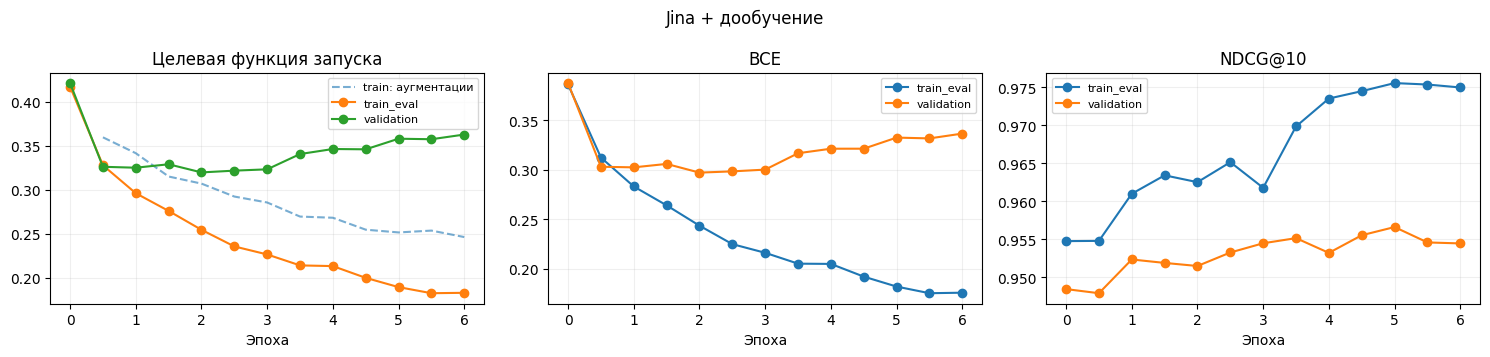

In [18]:
training_results = {}
base_result, base_val_scores = run_training(BASE_EXPERIMENT)
training_results[BASE_EXPERIMENT['name']] = base_result
add_candidate('jina_finetuned', 'Jina + дообучение', base_val_scores, kind='neural',
               checkpoint=base_result['checkpoint'], best_epoch=base_result['best_epoch'],
               loss='BCE + 0.2 × ranking')


## 8. Jina с BM25 и бустингом

Бустинг обучаю на лексических признаках и метаданных с группировкой по запросам.
Скор дообученной Jina не входит в его обучающие признаки, поэтому здесь не нужны
OOF-предсказания нейросети. Сначала получаю два независимых скора, затем смешиваю их.

Перед смешиванием нормирую скоры внутри запроса. Вес добавки выбираю из небольшой
фиксированной сетки по validation. Эта validation используется для выбора моделей
и настроек; итоговую оценку на test даёт соревнование.


[100]	train's ndcg@10: 0.820908	validation's ndcg@10: 0.762184


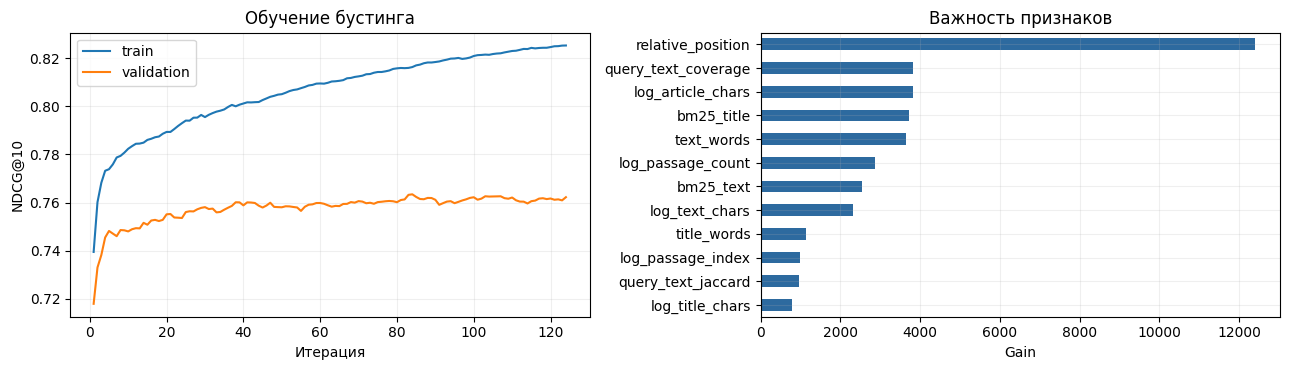

In [19]:
booster = lgb.LGBMRanker(
    objective='lambdarank', metric='ndcg', label_gain=[0, 1],
    n_estimators=500, learning_rate=0.05, num_leaves=15, max_depth=4,
    min_child_samples=80, reg_lambda=5.0, random_state=SEED,
    verbosity=-1, n_jobs=2, deterministic=True, force_col_wise=True,
)
train_groups = train.groupby('query_id', sort=False).size().tolist()
val_groups = val.groupby('query_id', sort=False).size().tolist()
booster.fit(
    X_train, train.relevance.to_numpy(), group=train_groups,
    eval_set=[(X_train, train.relevance.to_numpy()), (X_val, val.relevance.to_numpy())],
    eval_group=[train_groups, val_groups], eval_names=['train', 'validation'], eval_at=[10],
    callbacks=[lgb.early_stopping(40, verbose=False), lgb.log_evaluation(100)],
)
boost_val_scores = booster.predict(X_val, num_iteration=booster.best_iteration_)
booster.booster_.save_model(str(WORK_DIR / 'lightgbm_ranker.txt'))
add_candidate('boosting', 'Бустинг: лексика и метаданные', boost_val_scores, kind='boosting')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name, values in booster.evals_result_.items():
    metric = values['ndcg@10']
    axes[0].plot(np.arange(1, len(metric)+1), metric, label=name)
axes[0].set(xlabel='Итерация', ylabel='NDCG@10', title='Обучение бустинга')
axes[0].legend()
importance = pd.Series(booster.booster_.feature_importance(importance_type='gain'), index=X_train.columns)
importance.nlargest(12).sort_values().plot.barh(ax=axes[1], color='#2D6A9F')
axes[1].set(title='Важность признаков', xlabel='Gain')
fig.tight_layout()
fig.savefig(WORK_DIR / 'boosting_diagnostics.png', dpi=140, bbox_inches='tight')
plt.show()


Jina + BM25


,weight,ndcg10
0,0.00,0.956602
1,0.10,0.953517
2,0.25,0.945407
3,0.50,0.893349


Jina + бустинг


,weight,ndcg10
0,0.00,0.956602
1,0.10,0.955344
2,0.25,0.953478
3,0.50,0.923005


,model,ndcg10,best_epoch,blend_weight
2,Jina + дообучение,0.956602,5.0,NaN
4,Jina + BM25,0.956602,NaN,0.0
5,Jina + бустинг,0.956602,NaN,0.0
1,Jina без дообучения,0.948439,NaN,NaN
3,Бустинг: лексика и метаданные,0.763407,NaN,NaN
0,BM25,0.660480,NaN,NaN


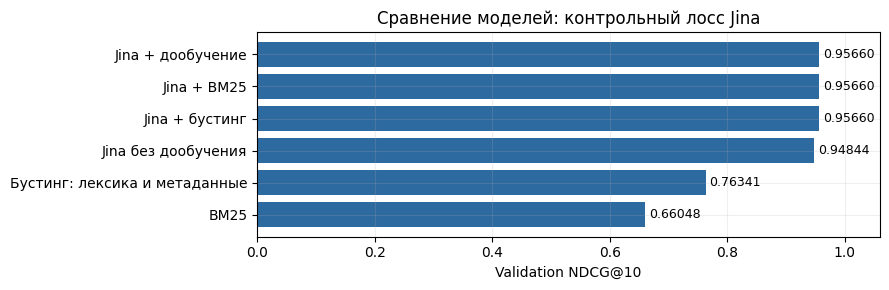

In [20]:
def normalize_within_query(frame, scores):
    values = pd.Series(np.asarray(scores, dtype=np.float64))
    groups = pd.Series(frame.query_id.to_numpy())
    means = values.groupby(groups, sort=False).transform('mean')
    stds = values.groupby(groups, sort=False).transform('std', ddof=0)
    return ((values-means)/stds.clip(lower=1e-8)).to_numpy(dtype=np.float32)

def mix_scores(frame, neural_scores, auxiliary_scores, weight):
    # Нулевой вес сохраняет исходные скоры, включая порядок совпадений.
    if weight == 0:
        return np.asarray(neural_scores, dtype=np.float32).copy()
    neural = normalize_within_query(frame, neural_scores)
    auxiliary = normalize_within_query(frame, auxiliary_scores)
    return ((1-weight)*neural+weight*auxiliary).astype(np.float32)

def select_blend(key, label, auxiliary_scores, auxiliary_kind):
    rows, predictions = [], []
    for weight in BLEND_WEIGHTS:
        scores = mix_scores(val, base_val_scores, auxiliary_scores, weight)
        rows.append(dict(weight=weight, ndcg10=float(query_ndcg(val, scores).mean())))
        predictions.append(scores)
    table = pd.DataFrame(rows)
    best_position = int(table.ndcg10.to_numpy().argmax())
    weight = float(table.iloc[best_position].weight)
    add_candidate(key, label, predictions[best_position], kind='blend',
        auxiliary_kind=auxiliary_kind, blend_weight=weight, checkpoint=base_result['checkpoint'])
    table.to_csv(WORK_DIR / f'{key}_weights.csv', index=False)
    print(label)
    display(table.round(6))
    return table

bm25_blend_table = select_blend('jina_bm25', 'Jina + BM25', bm25_val_scores, 'bm25')
boost_blend_table = select_blend('jina_boosting', 'Jina + бустинг', boost_val_scores, 'boosting')
STAGE_ONE_KEYS = list(candidate_info)
plot_comparison(STAGE_ONE_KEYS, 'Сравнение моделей: контрольный лосс Jina', 'models_comparison.png')


### Примеры ранжирования

Показываю несколько фиксированных validation-запросов: скоры разных методов,
порядок документов и настоящую релевантность


In [21]:
output_queries = np.random.default_rng(SEED).choice(val.query_id.unique(), size=3, replace=False)

def show_rankings(key, query_ids, top_n=5):
    ranked = val[['id', 'query_id', 'query_clean', 'title_clean', 'text_clean', 'relevance']].copy()
    ranked['score'] = val_predictions[key]
    ranked['Jina без дообучения'] = val_predictions['jina_pretrained']
    ranked['Jina с дообучением'] = val_predictions['jina_finetuned']
    ranked['BM25'] = val_predictions['bm25']
    ranked['document'] = ranked.text_clean.str.slice(0, 300)
    for query_id in query_ids:
        group = ranked.loc[ranked.query_id.eq(query_id)].sort_values(
            ['score', 'id'], ascending=[False, True]).head(top_n)
        print('Запрос:', group.query_clean.iloc[0])
        print('Модель:', candidate_info[key]['label'])
        with pd.option_context('display.max_colwidth', 300):
            display(group[['title_clean', 'document', 'relevance', 'score',
                           'Jina без дообучения', 'Jina с дообучением', 'BM25']].round(4))

stage_one_best = comparison_table(STAGE_ONE_KEYS).iloc[0]['key']
show_rankings(stage_one_best, output_queries)


Запрос: Какое животное является символом демократов в США?
Модель: Jina + дообучение


,title_clean,document,relevance,score,Jina без дообучения,Jina с дообучением,BM25
19137,Демократическая партия (США),"Демократическая партия () — наряду с Республиканской, одна из двух крупнейших современных политических партий США. Является самой старой партией в США. Её неофициальный символ — ослик (символ упрямого преодоления препятствий и выносливости), неофициальный цвет — голубой.",1,3.2734,0.8228,3.2734,14.347600
15522,Белоголовый орлан,"В промежутке между двумя войнами (За независимость и Гражданской) изображение птицы доминировало в качестве символа США. Однако затем популярность этого атрибута снизилась до такой степени, что птицу зачастую стали рассматривать как вредителя: например, с 1917 по 1953 годы на Аляске за уничтожен...",0,-2.5117,-0.7539,-2.5117,4.176700
24093,Список символов штатов США (млекопитающие),"Список млекопитающих - символов штатов США включает в себя млекопитающих, признанных официальными символами того или иного штата США. В некоторых штатах существует несколько таких символов - обычное млекопитающее, морское млекопитающее и домашнее животное. В некоторых штатах символа-млекопитающе...",0,-4.4453,-1.0957,-4.4453,29.563900
9496,Список символов штатов США (птицы),"Начало выбору птиц в качестве национальных символов было положено ещё в 1782 году, когда официальным символом США (Национальной птицей, National Bird) американским Конгрессом после шестилетних ожесточённых дебатов был выбран белоголовый орлан (""Haliaeetus leucocephalus""). Выбор птиц в качестве с...",0,-4.6250,-1.2432,-4.6250,14.923400
2919,Список символов штатов США (рептилии),"Двадцать шесть штатов США выбрали рептилий своими официальными символами. Первой стала Оклахома, избравшей в 1969 году своим символом ошейниковую пустынную игуану. Рептилия получает статус символа только после её избрания законодательным органом штата. Девятнадцать из двадцати шести рептилий явл...",0,-5.5156,-1.5029,-5.5156,17.114201


Запрос: Тренером какой сборной был Марадонна?
Модель: Jina + дообучение


,title_clean,document,relevance,score,Jina без дообучения,Jina с дообучением,BM25
2669,"Марадона, Диего Армандо","С октября 2008 года по июль 2010 года Марадона работал главным тренером сборной Аргентины, с которой дошёл до четвертьфинала чемпионата мира 2010 года.",1,4.2148,1.2373,4.2148,17.717899
29946,"Марадона, Диего Армандо","12 марта 1983 года Марадона вновь вышел на поле в матче с «Бетисом». В этом матче «Барселоной» впервые руководил новый главный тренер «Барселоны» и бывший наставник Марадоны в сборной Аргентины, Сесар Луис Менотти. Его приход на тренерский мостик «сине-гранатовых» Диего поддержал: бывший главный...",0,4.1250,1.2178,4.1250,9.056300
9755,"Марадона, Диего Армандо","17 октября 2008 года, после того как Альфио Басиле подал в отставку по личным мотивам, Марадона вновь высказался о своём желании возглавить сборную Аргентины. 28 октября он встретился с Хулио Грондоной, президентом аргентинской футбольной ассоциации, где ему предложили возглавить национальную ко...",1,2.6348,1.2900,2.6348,14.765800
15147,"Марадона, Диего Армандо","В декабре 2010 года Марадона стал кандидатом на пост главного тренера клуба «Блэкберн Роверс», а также сборной Ирана; однако обе команды Диего так и не принял. Чтобы продолжить тренерскую карьеру, в феврале 2011 года Марадона заключил контракт с агентской компанией Хорхе Мендеса, занимающейся де...",0,2.5371,0.9385,2.5371,6.285700
30597,"Марадона, Диего Армандо","В 1977 году Сесар Луис Менотти, главный тренер сборной Аргентины, вызвал Марадону на товарищеский матч со сборной Венгрии, проходивший 27 февраля. Марадона вышел за 20 минут до конца встречи, заменив Леопольдо Луке, но ничем особенным себя не проявил. Сам Диего остался недоволен своей игрой в эт...",0,1.8525,0.7197,1.8525,9.946900


Запрос: Где происходит действие The Elder Scrolls IV: Oblivion?
Модель: Jina + дообучение


,title_clean,document,relevance,score,Jina без дообучения,Jina с дообучением,BM25
4080,The Elder Scrolls IV: Oblivion,"Главная › Энциклопедия\n\nИгра является частью серии ""The Elder Scrolls"". Её действие происходит в вымышленной провинции Сиродил, в столице Тамриэльской империи — Имперском городе — и его окрестностях. В соответствии с сюжетом игры главный герой противостоит организации «Мифический Рассвет», пок...",1,5.6797,2.3125,5.6797,51.633801
31132,The Elder Scrolls IV: Oblivion,"Действие Oblivion происходит после событий , хотя игра не является прямым сиквелом к нему или к другим играм серии. Местом действия является Сиродил, центральная провинция Тамриэля, континента, на котором разворачиваются события всех игр серии.",1,5.4648,2.0684,5.4648,52.727798
10206,The Elder Scrolls,"Вселенная The Elder Scrolls поделена на несколько плоскостей бытия. Действие игр серии The Elder Scrolls происходит в одной из них — планете ""Нирн"", а также в параллельном плане — ""Обливионе"" (), поделенном на несколько областей, каждой из которой правит Принц Даэдра. Нирн представляет собой пла...",1,1.6680,0.1184,1.6680,41.389702
31141,The Elder Scrolls IV: Oblivion,"Загрузка локаций с остановкой игрового процесса происходит только при переходе из интерьера в экстерьер и при использовании быстрых путешествий.\nИгровой мир ограничен невидимой стеной, но для большинства мест, ограничивающих игровое пространство, характерны физические барьеры — горы. При подход...",0,-4.5664,0.2832,-4.5664,30.545700
21883,The Elder Scrolls IV: Oblivion,"Главная сюжетная линия состоит из серии связанных между собой квестов, иногда перекрещивающихся с квестами других типов. Игра начинается с пролога, в ходе которого игрока знакомят с основными особенностями геймплея в виде всплывающих подсказок. После обучения игрок выходит на свободу в открытый ...",0,-5.0391,-0.1448,-5.0391,25.962999


## 9. Сравнение лоссов при дообучении Jina

Для этой части фиксирую Jina с дообучением без BM25 и бустинга, чтобы отдельно
оценить влияние лосса. Контроль уже обучен выше. Два новых запуска начинают
с тех же pretrained-весов, с теми же seed, данными и настройками AdamW.

Значения разных целевых функций напрямую не сравниваю. Общие показатели —
validation NDCG@10 и BCE; лучший checkpoint выбираю по NDCG@10


Jina + NDCGLoss2++ | обучаемых параметров: 14.767 млн


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,0.0,None,0.38603,0.38746,0.95475,0.94844


Jina + NDCGLoss2++: эпоха 1/6:   0%|          | 0/2586 [00:00<?, ?it/s]

,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,0.50039,0.35266,0.31345,0.30385,0.95478,0.9476


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,1.0,0.33519,0.28152,0.30181,0.96098,0.95238


Эпоха 1: лучший NDCG@10 0.952377; patience 0/2; AMP-пропусков 2


... (16 outputs left out)

Jina + NDCGLoss2++: эпоха 6/6:   0%|          | 0/2586 [00:00<?, ?it/s]

,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,5.50039,0.24731,0.1751,0.33238,0.97737,0.9545


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,6.0,0.24204,0.17544,0.33713,0.97737,0.95559


Эпоха 6: лучший NDCG@10 0.956326; patience 1/2; AMP-пропусков 0


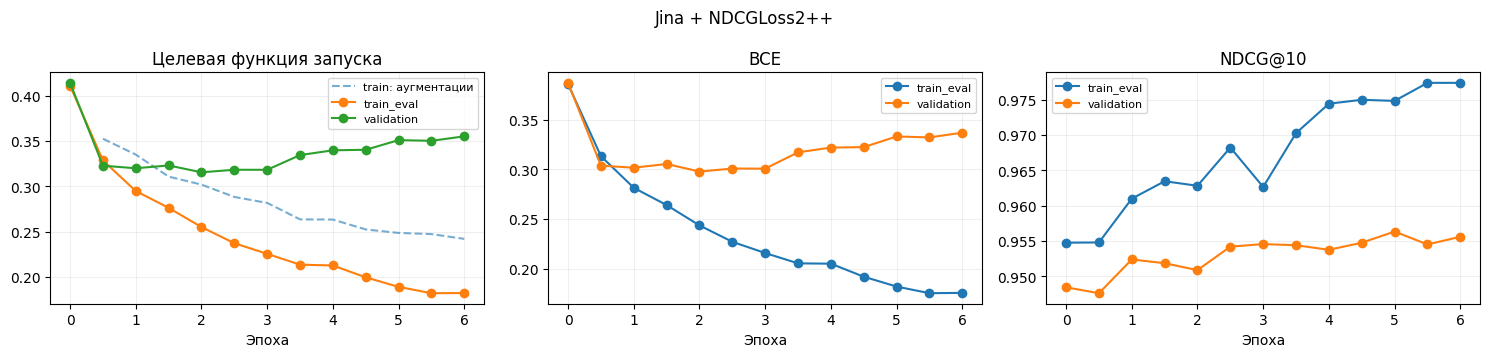

Jina + contrastive | обучаемых параметров: 14.767 млн


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,0.0,None,0.38603,0.38746,0.95475,0.94844


Jina + contrastive: эпоха 1/6:   0%|          | 0/2586 [00:00<?, ?it/s]

,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,0.50039,0.36859,0.31325,0.30425,0.95767,0.94846


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,1.0,0.34994,0.2817,0.30276,0.96138,0.95156


Эпоха 1: лучший NDCG@10 0.951560; patience 0/2; AMP-пропусков 2


... (16 outputs left out)

Jina + contrastive: эпоха 6/6:   0%|          | 0/2586 [00:00<?, ?it/s]

,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,5.50039,0.25703,0.17374,0.33436,0.97977,0.95571


,epoch,train_loss,train_eval_bce,val_bce,train_eval_ndcg10,val_ndcg10
0,6.0,0.25129,0.17399,0.33908,0.97977,0.954


Эпоха 6: лучший NDCG@10 0.956538; patience 1/2; AMP-пропусков 0


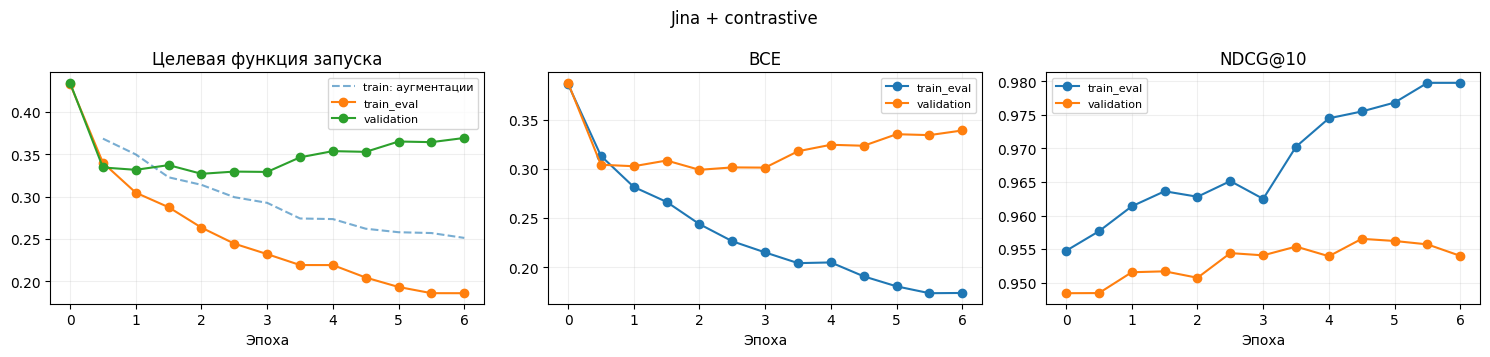

,model,ndcg10,best_epoch,blend_weight
0,Jina + дообучение,0.956602,5.000000,None
2,Jina + contrastive,0.956538,4.500387,None
1,Jina + NDCGLoss2++,0.956326,5.000000,None


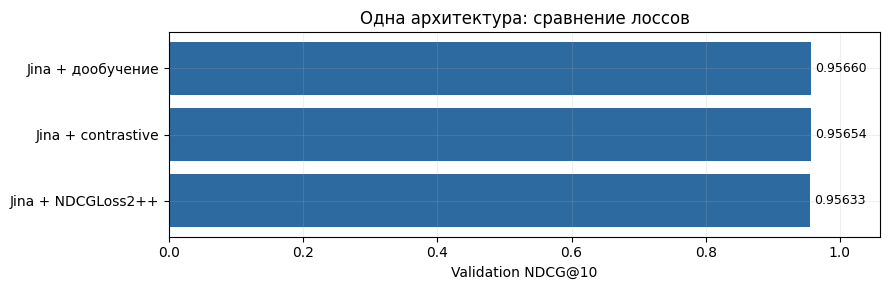

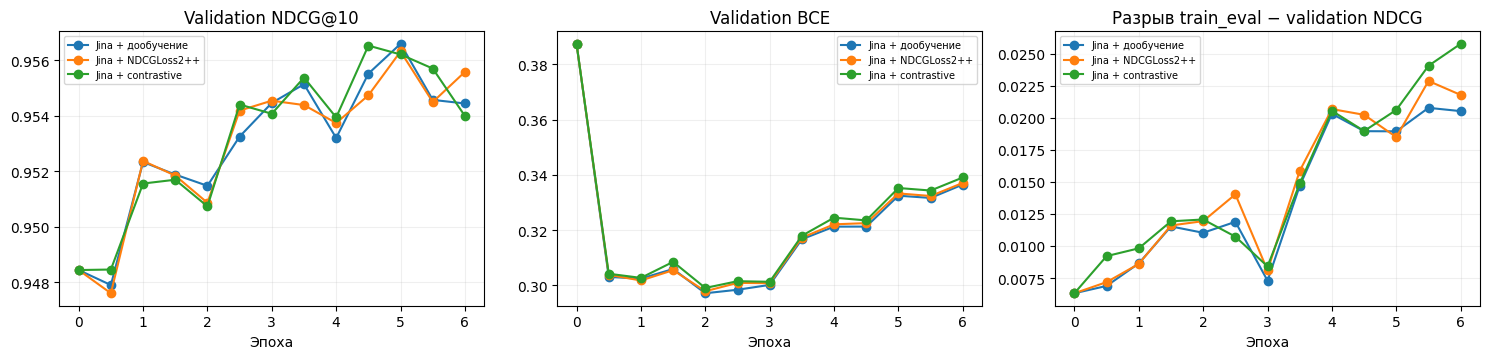

In [22]:
for experiment in LOSS_EXPERIMENTS:
    result, scores = run_training(experiment)
    training_results[experiment['name']] = result
    add_candidate(experiment['name'], experiment['label'], scores, kind='neural',
        checkpoint=result['checkpoint'], best_epoch=result['best_epoch'],
        loss=experiment['auxiliary'], loss_weight=experiment['aux_weight'])

loss_keys = ['jina_finetuned'] + [experiment['name'] for experiment in LOSS_EXPERIMENTS]
plot_comparison(loss_keys, 'Одна архитектура: сравнение лоссов', 'loss_comparison.png')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.7))
for key in loss_keys:
    history = pd.DataFrame(training_results[key]['history'])
    label = candidate_info[key]['label']
    axes[0].plot(history.epoch, history.val_ndcg10, 'o-', label=label)
    axes[1].plot(history.epoch, history.val_bce, 'o-', label=label)
    axes[2].plot(history.epoch, history.train_eval_ndcg10-history.val_ndcg10, 'o-', label=label)
axes[0].set_title('Validation NDCG@10')
axes[1].set_title('Validation BCE')
axes[2].set_title('Разрыв train_eval − validation NDCG')
for axis in axes:
    axis.set_xlabel('Эпоха')
    axis.legend(fontsize=7)
fig.tight_layout()
fig.savefig(WORK_DIR / 'loss_training_curves.png', dpi=140, bbox_inches='tight')
plt.show()


## 10. Итоговое сравнение и примеры ошибок

Сопоставляю все варианты на одной validation. При одинаковой метрике сохраняю
более ранний вариант: дообучение без добавок стоит перед смесями.
Модель для test выбирается автоматически по этой таблице.


,model,ndcg10,best_epoch,blend_weight
2,Jina + дообучение,0.956602,5.000000,NaN
4,Jina + BM25,0.956602,NaN,0.0
5,Jina + бустинг,0.956602,NaN,0.0
7,Jina + contrastive,0.956538,4.500387,NaN
6,Jina + NDCGLoss2++,0.956326,5.000000,NaN
1,Jina без дообучения,0.948439,NaN,NaN
3,Бустинг: лексика и метаданные,0.763407,NaN,NaN
0,BM25,0.660480,NaN,NaN


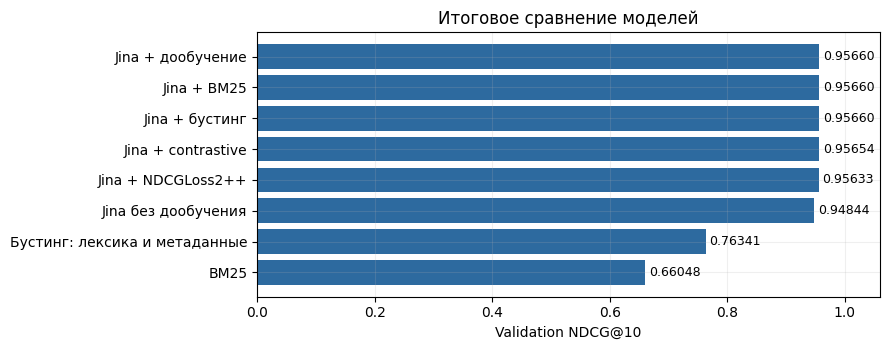

Выбранная модель: Jina + дообучение
Validation NDCG@10: 0.956602


,better,worse,unchanged,mean_delta
0,62,56,338,0.008164


Запросы с наименьшим NDCG выбранной модели:
Запрос: Какая валюта в Дагестане?
Модель: Jina + дообучение


,title_clean,document,relevance,score,Jina без дообучения,Jina с дообучением,BM25
19343,Революция и Гражданская война в Дагестане (март 1917 — май 1919),"""Каждая партия, а их было много, жаждала власти. Брали деньги ото всех, кто давал. Главной денежной валютой были «закавказские боны», выпускаемые под обеспечение нефтяных богатств Азербайджанским правительством совместно с Русским Национальным Советом, из Астрахани же снабжали обильно «керенками...",0,-3.3047,-1.0439,-3.3047,5.1508
9814,Дагестан,"Как и многие другие регионы РФ, Дагестан имеет прямые экономические связи со многими странами мира, в некоторых из которых республика открыла свои внешнеэкономические представительства. В 2012 году объём товарооборота между Дагестаном и Турцией достиг 47,6 млн долларов, что на 60,8 % выше показа...",0,-4.2344,-1.9297,-4.2344,0.1023
3821,Дагестан,"За три квартала 2014 года товарооборот между Азербайджаном и Дагестаном составил 136,84 миллиона долларов, при этом на импорт азербайджанской продукции пришлись 122,12 миллиона долларов, на экспорт в Азербайджан — 14,7 миллиона долларов. А с Ираном достиг 160 миллионов долларов.\nДо 2003 года гл...",0,-4.9844,-1.9609,-4.9844,0.0730
28785,Экономика Дагестана,"Импорт * за январь – сентябрь 2014 года составил 418,0 млн. долларов США, в том числе из стран дальнего зарубежья – 252,7 млн. долларов США, из государств –участников СНГ – 165,3 млн. долларов США\nстраны, производивших таможенное оформление товаров на таможенных постах нашего региона.",0,-5.1328,-2.0254,-5.1328,0.0825
1668,Туризм в Таджикистане,"Денежные средства на сумму свыше 500 долларов США или их эквиваленты в другой валюте должны быть декларированы по прибытии. Де-юре максимально разрешенная к ввозу денежная сумма составляет 5000 долларов США, но де-факто это правило в большинстве случаев не работает. Ввоз и вывоз национальной вал...",0,-5.3008,-1.3662,-5.3008,3.3097


Запрос: Какая максимальная скорость ЭР2?
Модель: Jina + дообучение


,title_clean,document,relevance,score,Jina без дообучения,Jina с дообучением,BM25
4113,Euro Truck Simulator 2 — Википедия,"В игре присутствуют временные и постоянные дорожные знаки, ограничивающие скоростной режим. Максимальная скорость всех грузовиков в игре по умолчанию ограничена технически до 90 км/ч (отключается в настройках игры). В исключительных случаях она может увеличиваться при движении на спусках и снижа...",0,0.0349,0.2563,0.0349,15.1760
19120,ЭР2,"В году рижский филиал Всесоюзного научно-исследовательского института вагоностроения, Прибалтийская железная дорога и Всесоюзный научно-исследовательский институт железнодорожного транспорта провели испытания по сравнению тягово-энергетических характеристик электропоездов серий ЭР2 и ЭР2. Резуль...",0,-2.9395,0.5298,-2.9395,0.0000
26173,ЭР2Р,Тяговые электродвигатели (ТЭД) модели 1ДТ-003.1 были унаследованы от поезда ЭР22В. Мощность часового режима ТЭД составляла 240 кВт при токе потребления 350 А. Частота вращения вала составляла:\nНа поезде применено опорно-рамное подвешивание ТЭД. Рекуперативное торможение на ЭР2Р возможно при сни...,0,-3.1875,-0.2205,-3.1875,0.0000
24433,ЭР1,"Сравнительно невысокое ускорение во время разгона поезда (0,45 м/с²), невысокая конструкционная скорость (85 км/ч) С уже к середине 1950-х годов начали сдерживать рост среднетехнических скоростей пригородного сообщения. Секции серии СН хоть и имели более высокую конструкционную скорость (130 км/...",1,-3.2402,-0.5674,-3.2402,7.4924
45,ЭР22,"В — годах РВЗ на базе ЭР10 спроектировал электропоезд ЭР20. На этих поездах предполагалось применить двигатели увеличенной мощности по 220 кВт, а конструкционную скорость электропоезда повысить до 160 км/ч. В процессе проектирования ЭР20 производились усовершенствования конструкции электрооборуд...",0,-3.3379,-0.7627,-3.3379,4.9965


Запрос: Когда был выпущен первый Ил-2?
Модель: Jina + дообучение


,title_clean,document,relevance,score,Jina без дообучения,Jina с дообучением,BM25
27115,И-2,"И-2 «истребитель второй» — истребитель-биплан, разработанный Дмитрием Григоровичем. Первый советский истребитель собственной конструкции в СССР. Результат отказа от производства неудачного прототипа «истребитель первый» Григоровича И-1. После глубокой модификации прототипа И-2 новый самолёт запу...",0,4.0156,1.5381,4.0156,14.607100
18066,И-2,Советский боевой самолёт-биплан «легкий истребитель первый» Григоровича И-1 «маневренный». Создан и построен в Москве Конструкторской бригадой под руководством Дмитрия Григоровича. Прототип выпущен в одном экземпляре в январе 1924 года.\nДерево-полотняный подкосный биплан оснащенный поршневым дв...,0,3.3438,1.5176,3.3438,16.368099
12186,Ил-2,"Первые серийные Ил-2 изготовлены в феврале 1941 года в Воронеже на заводе № 18 (в ноябре 1941 года завод эвакуирован в Куйбышев). Ил-2 серийно производился также на авиационных заводах № 1 и № 18 в Куйбышеве, на авиационном заводе № 30 в Москве. Из общего количества Ил-2 ( шт.) 74 % произведено ...",1,2.0801,1.3857,2.0801,33.957100
3801,Икарус ИК-2,"ИК-2 — югославский истребитель 1930-х годов. Созданный в 1931—1935 годах фирмой «Икарус» под руководством конструкторов Косты Сивчева и Любомира Илича, ИК-2 стал первым югославским истребителем собственной разработки. Серийное производство самолёта было начато в 1937 году, но ограничилось лишь п...",0,-4.9453,-1.1152,-4.9453,11.355000
4994,Ил-8,"Первый вариант Ил-8 (Ил-АМ-42) взлетел 10 мая 1943 года и был выполнен по схеме Ил-2, но имел более длинный (на 90 см) фюзеляж и увеличенную площадь крыла при том же, что у Ил-2 размахе (14,6 м). Кабина была цельнобронированной, вооружение — как на Ил-2, однако также предусматривалась крыльевая ...",0,-5.8359,-1.7549,-5.8359,34.975700


In [23]:
all_keys = list(candidate_info)
final_comparison = comparison_table(all_keys)
final_comparison.to_csv(WORK_DIR / 'final_comparison.csv', index=False)
plot_comparison(all_keys, 'Итоговое сравнение моделей', 'final_comparison.png')
best_key = str(final_comparison.iloc[0]['key'])
best_spec = candidate_info[best_key]
save_json(WORK_DIR / 'selected_model.json', dict(key=best_key, **best_spec))
print('Выбранная модель:', best_spec['label'])
print('Validation NDCG@10:', round(best_spec['ndcg10'], 6))

per_query = pd.DataFrame({candidate_info[key]['label']: query_ndcg(val, val_predictions[key])
                          for key in all_keys})
per_query.to_csv(WORK_DIR / 'per_query_ndcg.csv')
baseline_ndcg = query_ndcg(val, val_predictions['jina_pretrained'])
selected_ndcg = query_ndcg(val, val_predictions[best_key])
delta = selected_ndcg-baseline_ndcg
display(pd.DataFrame([dict(
    better=int(delta.gt(1e-12).sum()), worse=int(delta.lt(-1e-12).sum()),
    unchanged=int(delta.abs().le(1e-12).sum()), mean_delta=float(delta.mean()))]).round(6))

hard_queries = selected_ndcg.sort_values(kind='stable').head(3).index.tolist()
print('Запросы с наименьшим NDCG выбранной модели:')
show_rankings(best_key, hard_queries)


### Краткие итоги

Смотрю на прибавку от дообучения, вклад дополнительных скоров и влияние лосса.
Все разницы ниже посчитаны на одной validation.


In [24]:
finetuning_gain = candidate_info['jina_finetuned']['ndcg10']-candidate_info['jina_pretrained']['ndcg10']
print(f'Дообучение относительно исходной Jina: {finetuning_gain:+.6f} NDCG@10.')
for key in ['jina_bm25', 'jina_boosting']:
    info = candidate_info[key]
    gain = info['ndcg10']-candidate_info['jina_finetuned']['ndcg10']
    print(f"{info['label']}: {gain:+.6f} относительно дообучения; вес добавки {info['blend_weight']:g}.")
best_loss_key = str(comparison_table(loss_keys).iloc[0]['key'])
loss_gain = candidate_info[best_loss_key]['ndcg10']-candidate_info['jina_finetuned']['ndcg10']
print(f"Лучший вариант лосса: {candidate_info[best_loss_key]['label']}; разница с контролем {loss_gain:+.6f}.")
print('Для submission выбрана:', best_spec['label'])


Дообучение относительно исходной Jina: +0.008164 NDCG@10.
Jina + BM25: +0.000000 относительно дообучения; вес добавки 0.
Jina + бустинг: +0.000000 относительно дообучения; вес добавки 0.
Лучший вариант лосса: Jina + дообучение; разница с контролем +0.000000.
Для submission выбрана: Jina + дообучение


## 11. Предсказания test

Использую выбранную модель и тот же препроцессинг. Для нейросети загружаю лучший
validation-checkpoint; для смеси сохраняю выбранный вес

In [25]:
def predict_selected_model(frame, spec):
    kind = spec['kind']
    auxiliary = None
    if kind in {'bm25', 'boosting', 'blend'}:
        features = feature_builder.transform(frame)
        if kind == 'bm25' or (kind == 'blend' and spec['auxiliary_kind'] == 'bm25'):
            auxiliary = features.bm25_title.to_numpy()+features.bm25_text.to_numpy()
        else:
            auxiliary = booster.predict(features, num_iteration=booster.best_iteration_)
        if kind in {'bm25', 'boosting'}:
            return np.asarray(auxiliary, dtype=np.float32)

    q_parts, t_parts, x_parts = tokenize_frame(frame)
    inputs = [build_pair_input(q, t, x) for q, t, x in zip(q_parts, t_parts, x_parts)]
    checkpoint = spec.get('checkpoint')
    settings = None
    saved = None
    if checkpoint is not None:
        saved = torch.load(checkpoint, map_location='cpu', weights_only=True)
        settings = saved['config']
    model = load_jina(settings)
    if saved is not None:
        load_partial_weights(model, saved['weights'])
    model.requires_grad_(False)
    try:
        neural = predict_scores(model, make_score_loader(inputs))
    finally:
        del model, saved, inputs, q_parts, t_parts, x_parts
        gc.collect()
        torch.cuda.empty_cache()
    if kind == 'blend':
        return mix_scores(frame, neural, auxiliary, spec['blend_weight'])
    return neural

if MAKE_SUBMISSION:
    test_scores = predict_selected_model(test, best_spec)
    if not np.isfinite(test_scores).all() or len(test_scores) != len(test):
        raise ValueError('Некорректные test-предсказания.')
    submission = pd.DataFrame({'id': test.id.to_numpy(), 'prediction': test_scores})
    template_path = next((DATA_DIR / name for name in ['sample_submissions.csv', 'sample_submission.csv']
                          if (DATA_DIR / name).exists()), None)
    if template_path is not None:
        template = pd.read_csv(template_path, dtype={'id': str})
        if template.id.duplicated().any() or set(template.id) != set(test.id):
            raise ValueError('id в submission-шаблоне отличаются от test.')
        submission = submission.set_index('id').reindex(template.id).reset_index()
    submission_path = WORK_DIR.parent / 'sample_submissions.csv'
    submission.to_csv(submission_path, index=False)
    print('Модель:', best_spec['label'], '| строк:', len(submission))
    display(submission.head())
    display(FileLink(str(submission_path)))
else:
    print('Для формирования CSV включите MAKE_SUBMISSION=True в настройках.')


Токенизация:   0%|          | 0/53 [00:00<?, ?it/s]

Модель: Jina + дообучение | строк: 13507


,id,prediction
0,r_00100bd94cf8513c6500,3.187500
1,r_0011d1a81cda1b1c720f,-4.343750
2,r_00135550b108ebd88432,-6.023438
3,r_001cac3cb24c86e57ef0,-6.089844
4,r_001e8de6d4886f85b86e,-3.230469


/kaggle/working/sample_submissions.csv

## 12. Сохранение результатов


In [26]:
report_path = WORK_DIR.parent / 'ranking_results.zip'
with zipfile.ZipFile(report_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(WORK_DIR.rglob('*')):
        if path.is_file() and path.suffix in {'.csv', '.json', '.png', '.txt'}:
            archive.write(path, path.relative_to(WORK_DIR))
print('Результаты:', report_path)
display(FileLink(str(report_path)))


Результаты: /kaggle/working/ranking_results.zip


/kaggle/working/ranking_results.zip